<a href="https://colab.research.google.com/github/JonathanDLCH/Crypto_DataAnalysis/blob/main/Experimento_Personas_Desaparecidas_dataset_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 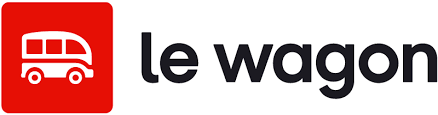

# Desafio - Exploracion Independiente

En los ejercicios anteriores trabajaste con datasets guiados paso a paso. Ahora es tu turno de aplicar todo lo que aprendiste de forma **independiente**.

Tu mision: elegir un dataset real, cargarlo, explorarlo, limpiarlo y visualizarlo. Este ejercicio sigue el mismo flujo que practicaste en las notebooks de Produccion de Petroleo y Gas y Stock Market API, pero esta vez **tu decides que hacer en cada paso**.

Si necesitas recordar como hacer algo, consulta las notebooks anteriores como referencia.

## Paso 1: Buscar y elegir un dataset en Kaggle

Ve a [Kaggle Datasets](https://www.kaggle.com/datasets) y busca un dataset que te interese. Necesitaras una cuenta de Kaggle (es gratuita).

**Tips para elegir un buen dataset:**
- Que tenga al menos unos cientos de filas para que el analisis sea interesante
- Que tenga columnas variadas: numericas, categoricas, y si es posible alguna columna de fecha
- Que sea un tema que te motive: deportes, finanzas, clima, musica, salud, videojuegos, etc.
- Que este en formato CSV (es el mas facil de cargar)

Algunas ideas si no sabes por donde empezar:
- Datos de ventas de videojuegos
- Estadisticas de jugadores de futbol
- Precios historicos de criptomonedas
- Datos climaticos de ciudades
- Rankings de peliculas o series

## Paso 2: Descargar y cargar los datos

1. En Kaggle, haz clic en el boton **Download** para descargar el archivo CSV (o ZIP).
2. Si descargaste un ZIP, descomprimelo en tu computadora para obtener los archivos CSV.
3. En Google Colab, haz clic en el **icono de carpeta** en la barra lateral izquierda para abrir el panel de archivos.
4. Arrastra los archivos CSV directamente al panel de archivos de Colab, o haz clic en el icono de **subir archivo** dentro del panel.
5. Espera a que la subida se complete antes de continuar.

> **Nota:** Los archivos subidos al panel de Colab son temporales. Si el runtime se desconecta, deberas subirlos de nuevo.

**Objetivo:** Importa las librerias que vas a necesitar y carga tu archivo CSV en un DataFrame.

In [27]:
# Importa las librerias necesarias
import pandas as pd
import numpy as np
import plotly.express as px

In [5]:
# Carga tu archivo CSV en un DataFrame
dfPersonasDesaparecidas = pd.read_csv('PersonasDesaparecidas.csv')

## Paso 3: Exploracion inicial

Antes de hacer cualquier analisis, necesitas conocer tu dataset. Responde estas preguntas:

- ¿Cuantas filas y columnas tiene?
- ¿Como se llaman las columnas?
- ¿Que tipo de dato tiene cada columna?
- ¿Como se ven las primeras filas?
- ¿Cuales son las estadisticas descriptivas basicas (media, min, max, etc.)?

In [6]:
# Explora la estructura de tu dataset
print('Rows x Columns',dfPersonasDesaparecidas.shape)
print(dfPersonasDesaparecidas.columns)
print(dfPersonasDesaparecidas.dtypes)
dfPersonasDesaparecidas.head()


Rows x Columns (52183, 11)
Index(['ID_VICTIMA', 'ORIGEN_REPORTE', 'FECHA_NACIMIENTO', 'SEXO',
       'FECHA_DESAPARICION', 'FECHA_REGISTRO', 'ESTATUS_VICTIMA', 'CVE_ENT',
       'ENTIDAD', 'CVE_MUN', 'MUNICIPIO'],
      dtype='object')
ID_VICTIMA             object
ORIGEN_REPORTE         object
FECHA_NACIMIENTO       object
SEXO                   object
FECHA_DESAPARICION     object
FECHA_REGISTRO         object
ESTATUS_VICTIMA        object
CVE_ENT               float64
ENTIDAD                object
CVE_MUN               float64
MUNICIPIO              object
dtype: object


,ID_VICTIMA,ORIGEN_REPORTE,FECHA_NACIMIENTO,SEXO,FECHA_DESAPARICION,FECHA_REGISTRO,ESTATUS_VICTIMA,CVE_ENT,ENTIDAD,CVE_MUN,MUNICIPIO
0,DE238A20-5D12-4FC5-9584-03FDA1118B72,COMISION LOCAL DE BUSQUEDA DE PERSONAS DEL EST...,1970-12-12,HOMBRE,2025-11-29 17:00:00,2025-11-29 17:00:00,DESAPARECIDA,15.0,ESTADO DE MÉXICO,76.0,SAN MATEO ATENCO
1,8CDD9EDF-0C1A-4891-ACB5-294A56CAC4A6,COMISION LOCAL DE BUSQUEDA DE PERSONAS DEL EST...,2009-05-12,MUJER,2025-11-29 10:00:00,2025-11-29 10:00:00,DESAPARECIDA,15.0,ESTADO DE MÉXICO,58.0,NEZAHUALCÓYOTL
2,3BD9FD3A-2F96-4113-ADFF-CEED64615D33,FISCALIA GENERAL DE TABASCO,1985-08-02,MUJER,2025-12-01 12:00:00,2025-12-01 13:00:00,DESAPARECIDA,27.0,TABASCO,8.0,HUIMANGUILLO
3,F9531527-BBFE-474D-B057-AAE13D21AB0A,FISCALIA GENERAL DE TABASCO,CONFIDENCIAL,CONFIDENCIAL,CONFIDENCIAL,CONFIDENCIAL,CONFIDENCIAL,27.0,TABASCO,999.0,CONFIDENCIAL
4,CE93CB7E-8382-4970-8E0E-D01323C6C824,FISCALIA GENERAL DE SINALOA,1951-01-08,HOMBRE,2025-11-30 15:00:00,2025-11-30 15:00:00,DESAPARECIDA,25.0,SINALOA,1.0,AHOME


In [7]:
# Obtiene las estadisticas descriptivas
dfPersonasDesaparecidas.describe()

,CVE_ENT,CVE_MUN
count,52182.000000,52182.000000
mean,16.934134,480.863938
std,10.615459,477.926575
min,1.000000,1.000000
25%,10.000000,21.000000
50%,15.000000,114.000000
75%,25.000000,999.000000
max,99.000000,999.000000


## Paso 4: Calidad de datos

Ahora evalua si tus datos estan limpios. Investiga:

- ¿Hay valores faltantes? ¿En que columnas?
- ¿Hay filas duplicadas?
- ¿Los tipos de datos son correctos? (por ejemplo, ¿una columna que deberia ser fecha esta como texto?)

In [8]:
# Revisa la calidad de tus datos
print('Datos nulos\n',dfPersonasDesaparecidas.isnull().sum())
print('Columnas duplicadas\n',dfPersonasDesaparecidas.duplicated().sum())

print('Tipos de datos')
dfPersonasDesaparecidas.dtypes


Datos nulos
 ID_VICTIMA               0
ORIGEN_REPORTE           0
FECHA_NACIMIENTO      3058
SEXO                     0
FECHA_DESAPARICION     483
FECHA_REGISTRO          71
ESTATUS_VICTIMA          1
CVE_ENT                  1
ENTIDAD                  1
CVE_MUN                  1
MUNICIPIO                1
dtype: int64
Columnas duplicadas
 0
Tipos de datos


,0
ID_VICTIMA,object
ORIGEN_REPORTE,object
FECHA_NACIMIENTO,object
SEXO,object
FECHA_DESAPARICION,object
FECHA_REGISTRO,object
ESTATUS_VICTIMA,object
CVE_ENT,float64
ENTIDAD,object
CVE_MUN,float64


## Paso 5: Limpieza y transformacion

Basandote en lo que descubriste en el paso anterior, limpia y prepara tus datos para el analisis. Algunas acciones comunes:

- Convertir columnas de fecha al tipo correcto
- Eliminar columnas que no son relevantes para tu analisis
- Renombrar columnas con nombres confusos
- Decidir que hacer con los valores nulos (eliminarlos, rellenarlos, o dejarlos)
- Eliminar filas duplicadas si las hay

In [9]:
#Cambios de tipo de datos
dfPersonasDesaparecidas['FECHA_NACIMIENTO'] = pd.to_datetime(dfPersonasDesaparecidas['FECHA_NACIMIENTO'], errors='coerce')
dfPersonasDesaparecidas['FECHA_DESAPARICION'] = pd.to_datetime(dfPersonasDesaparecidas['FECHA_DESAPARICION'], errors='coerce')
dfPersonasDesaparecidas['FECHA_REGISTRO'] = pd.to_datetime(dfPersonasDesaparecidas['FECHA_REGISTRO'], errors='coerce')
dfPersonasDesaparecidas.dtypes

,0
ID_VICTIMA,object
ORIGEN_REPORTE,object
FECHA_NACIMIENTO,datetime64[ns]
SEXO,object
FECHA_DESAPARICION,datetime64[ns]
FECHA_REGISTRO,datetime64[ns]
ESTATUS_VICTIMA,object
CVE_ENT,float64
ENTIDAD,object
CVE_MUN,float64


In [10]:
# Limpia y transforma tus datos
dfDates = dfPersonasDesaparecidas.copy()
dfDates = dfDates.drop(columns=['ID_VICTIMA','ORIGEN_REPORTE','CVE_ENT','CVE_MUN'])
dfDates.head()

,FECHA_NACIMIENTO,SEXO,FECHA_DESAPARICION,FECHA_REGISTRO,ESTATUS_VICTIMA,ENTIDAD,MUNICIPIO
0,1970-12-12,HOMBRE,2025-11-29 17:00:00,2025-11-29 17:00:00,DESAPARECIDA,ESTADO DE MÉXICO,SAN MATEO ATENCO
1,2009-05-12,MUJER,2025-11-29 10:00:00,2025-11-29 10:00:00,DESAPARECIDA,ESTADO DE MÉXICO,NEZAHUALCÓYOTL
2,1985-08-02,MUJER,2025-12-01 12:00:00,2025-12-01 13:00:00,DESAPARECIDA,TABASCO,HUIMANGUILLO
3,NaT,CONFIDENCIAL,NaT,NaT,CONFIDENCIAL,TABASCO,CONFIDENCIAL
4,1951-01-08,HOMBRE,2025-11-30 15:00:00,2025-11-30 15:00:00,DESAPARECIDA,SINALOA,AHOME


In [11]:
print('Valores campo SEXO:\n',dfDates['SEXO'].unique())
print('Valores campo ESTATUS_VICTIMA:\n',dfDates['ESTATUS_VICTIMA'].unique())

print('Valores campo ENTIDAD:\n',dfDates['ENTIDAD'].unique())
print('Valores campo MUNICIPIO:\n',dfDates['MUNICIPIO'].unique().size)

Valores campo SEXO:
 ['HOMBRE' 'MUJER' 'CONFIDENCIAL' 'INDETERMINADO']
Valores campo ESTATUS_VICTIMA:
 ['DESAPARECIDA' 'CONFIDENCIAL' 'NO LOCALIZADA' nan]
Valores campo ENTIDAD:
 ['ESTADO DE MÉXICO' 'TABASCO' 'SINALOA' 'HIDALGO' 'CHIAPAS'
 'AGUASCALIENTES' 'MICHOACÁN' 'MORELOS' 'GUANAJUATO' 'CIUDAD DE MÉXICO'
 'VERACRUZ' 'BAJA CALIFORNIA' 'GUERRERO' 'SAN LUIS POTOSÍ' 'COAHUILA'
 'OAXACA' 'SONORA' 'DURANGO' 'CHIHUAHUA' 'NUEVO LEÓN' 'PUEBLA' 'QUERÉTARO'
 'CAMPECHE' 'JALISCO' 'QUINTANA ROO' 'BAJA CALIFORNIA SUR' 'NAYARIT'
 'YUCATÁN' 'TAMAULIPAS' 'TLAXCALA' 'ZACATECAS' 'SE DESCONOCE' 'COLIMA' nan]
Valores campo MUNICIPIO:
 1346


In [12]:
# 1. Creamos una copia para trabajar de forma segura
df_limpio = dfDates.copy()

# 2. Copiar fechas mutuas si una de ellas está vacía (NaN/NaT)
df_limpio['FECHA_DESAPARICION'] = df_limpio['FECHA_DESAPARICION'].fillna(df_limpio['FECHA_REGISTRO'])
df_limpio['FECHA_REGISTRO'] = df_limpio['FECHA_REGISTRO'].fillna(df_limpio['FECHA_DESAPARICION'])

# 3. Ahora sí, eliminamos filas donde 'SEXO', 'FECHA_DESAPARICION' o 'ENTIDAD' sigan siendo nulos
df_limpio = df_limpio.dropna(subset=['SEXO', 'FECHA_DESAPARICION', 'FECHA_REGISTRO'])

# 4. Limpiamos valores inconsistentes
valores_validos_sexo = ['HOMBRE', 'MUJER', 'CONFIDENCIAL', 'INDETERMINADO']
df_limpio = df_limpio[df_limpio['SEXO'].isin(valores_validos_sexo)]

valores_validos_estatus = ['DESAPARECIDA', 'CONFIDENCIAL', 'NO LOCALIZADA']
df_limpio = df_limpio[df_limpio['ESTATUS_VICTIMA'].isin(valores_validos_estatus)]

# 5. Mostramos el resultado de la nueva estrategia de limpieza
print("Dimensiones antes de limpiar:", dfDates.shape)
print("Dimensiones después de limpiar (rescatando fechas):", df_limpio.shape)
print("\nValores nulos restantes:")
print(df_limpio.isnull().sum())

Dimensiones antes de limpiar: (52183, 7)
Dimensiones después de limpiar (rescatando fechas): (28579, 7)

Valores nulos restantes:
FECHA_NACIMIENTO      3054
SEXO                     0
FECHA_DESAPARICION       0
FECHA_REGISTRO           0
ESTATUS_VICTIMA          0
ENTIDAD                  0
MUNICIPIO                0
dtype: int64


In [13]:
# Verificamos que los valores únicos ahora estén limpios
print('Valores limpios en SEXO:', df_limpio['SEXO'].unique())
print('Valores limpios en ESTATUS_VICTIMA:', df_limpio['ESTATUS_VICTIMA'].unique())
print('Cantidad de municipios únicos:', df_limpio['MUNICIPIO'].nunique())

Valores limpios en SEXO: ['HOMBRE' 'MUJER' 'INDETERMINADO']
Valores limpios en ESTATUS_VICTIMA: ['DESAPARECIDA' 'NO LOCALIZADA']
Cantidad de municipios únicos: 1344


In [14]:
startDate = df_limpio['FECHA_DESAPARICION'].min()
endDate = df_limpio['FECHA_DESAPARICION'].max()
print('Rango de fechas:', startDate, 'a', endDate)

Rango de fechas: 1961-05-07 12:00:00 a 2025-12-01 12:00:00


## Paso 6: Filtrado y seleccion

Enfocate en un subconjunto de tus datos que sea interesante para analizar. Algunas ideas:

- Filtrar por un rango de fechas especifico
- Seleccionar solo una categoria o grupo
- Quedarte con las columnas mas relevantes para tu pregunta de analisis
- Seleccionar los top N elementos segun algun criterio

In [15]:
# Ejemplo de filtrado: Seleccionamos solo los registros del Estado de México
# y donde el estatus de la víctima sea 'DESAPARECIDA'
df_filtrado = df_limpio[
    (df_limpio['ENTIDAD'] == 'ESTADO DE MÉXICO') &
    (df_limpio['ESTATUS_VICTIMA'] == 'DESAPARECIDA')
]

# Mostramos un resumen del subconjunto
print("Cantidad de registros filtrados:", len(df_filtrado))
print("Distribución por Sexo en este subconjunto:")
print(df_filtrado['SEXO'].value_counts())


Cantidad de registros filtrados: 4181
Distribución por Sexo en este subconjunto:
SEXO
HOMBRE           2668
MUJER            1511
INDETERMINADO       2
Name: count, dtype: int64


In [70]:
# Vista previa limpia del subconjunto de datos filtrados
display(df_filtrado.head())

,FECHA_NACIMIENTO,SEXO,FECHA_DESAPARICION,FECHA_REGISTRO,ESTATUS_VICTIMA,ENTIDAD,MUNICIPIO,EDAD,MENOR_EDAD
0,1970-12-12,HOMBRE,2025-11-29 17:00:00,2025-11-29 17:00:00,DESAPARECIDA,ESTADO DE MÉXICO,SAN MATEO ATENCO,54.965092,False
1,2009-05-12,MUJER,2025-11-29 10:00:00,2025-11-29 10:00:00,DESAPARECIDA,ESTADO DE MÉXICO,NEZAHUALCÓYOTL,16.550308,True
2,1985-08-02,MUJER,2025-12-01 12:00:00,2025-12-01 13:00:00,DESAPARECIDA,TABASCO,HUIMANGUILLO,40.331280,False
4,1951-01-08,HOMBRE,2025-11-30 15:00:00,2025-11-30 15:00:00,DESAPARECIDA,SINALOA,AHOME,74.893908,False
5,1984-09-28,HOMBRE,2025-11-28 12:00:00,2025-11-28 12:00:00,DESAPARECIDA,ESTADO DE MÉXICO,VALLE DE CHALCO SOLIDARIDAD,41.166324,False


## Paso 7: Visualizaciones

Crea **al menos 3 graficos diferentes** para entender tus datos visualmente. Cada grafico debe responder una pregunta concreta.

Tipos de graficos que puedes usar:
- **Grafico de linea:** ideal para ver tendencias a lo largo del tiempo
- **Grafico de barras:** para comparar cantidades entre categorias
- **Histograma:** para ver la distribucion de una variable numerica
- **Boxplot:** para comparar distribuciones entre grupos
- **Scatter plot:** para ver la relacion entre dos variables numericas

Antes de cada grafico, escribe un comentario con la pregunta que quieres responder.

In [45]:
# Grafico 1: ¿Como se comportaron las desapariciones en los ultimos años en estado de México?
# 1. Volvemos a generar df_filtrado de forma segura desde df_limpio
df_filtrado = df_limpio[
    (df_limpio['ENTIDAD'] == 'ESTADO DE MÉXICO') &
    (df_limpio['ESTATUS_VICTIMA'] == 'DESAPARECIDA')
].copy()

# 2. Extraemos el año de la fecha de desaparición
df_filtrado['AÑO_DESAPARICION'] = df_filtrado['FECHA_DESAPARICION'].dt.year

# 3. Agrupamos por Año y Sexo para contar los casos
df_evolucion = df_filtrado.groupby(['AÑO_DESAPARICION', 'SEXO']).size().reset_index(name='Cantidad')

# Filtramos para mostrar desde un año reciente para mejor visualización (ej. 2010 en adelante)
df_evolucion = df_evolucion[df_evolucion['AÑO_DESAPARICION'] >= 2010]

# 4. Graficamos la línea de tiempo
figLM = px.line(
    df_evolucion,
    x='AÑO_DESAPARICION',
    y='Cantidad',
    color='SEXO',
    title='Evolución anual de desapariciones en el Estado de México (2010 - 2025)',
    labels={'AÑO_DESAPARICION': 'Año', 'Cantidad': 'Número de personas'}
)
figLM.show()

In [53]:
# Grafico 2: ¿Cuales fueron los estados con mas desapariciones?
df_filtrado = df_limpio.copy()

figT5 = px.bar(
    df_filtrado,
    x=df_filtrado.groupby('ENTIDAD').size().sort_values(ascending=False).head(5).index,
    y=df_filtrado.groupby('ENTIDAD').size().sort_values(ascending=False).head(5),
    title='Estados con más desapariciones',
    labels={'x': 'Estado', 'y': 'Número de apariciones'}
)
figT5.show()


In [69]:
# Grafico 3: ¿Cuantas personas desaparecidas son menores de edad?
df_filtrado = df_limpio.copy()

# Calculamos la diferencia de tiempo y la convertimos a años
df_filtrado['EDAD'] = (df_filtrado['FECHA_DESAPARICION'] - df_filtrado['FECHA_NACIMIENTO']).dt.days / 365.25

# Clasificamos si es menor de edad (menor a 18 años)
df_filtrado['MENOR_EDAD'] = df_filtrado['EDAD'] < 26

# Graficamos
figT6 = px.pie(
    df_filtrado.dropna(subset=['EDAD']),
    names=df_filtrado['MENOR_EDAD'].map({True: 'Menor de edad', False: 'Mayor de edad'}),
    title='Distribución de personas desaparecidas Jovenes (-25 años)',
    hole=0.3
)
figT6.show()

In [58]:
# (Opcional) Grafico 4: ¿En que meses hubo mas desapariciones?
df_filtrado = df_limpio.copy()

# 1. Extraemos el mes y su nombre
df_filtrado['MES_NUM'] = df_filtrado['FECHA_DESAPARICION'].dt.month
df_filtrado['MES_NOMBRE'] = df_filtrado['FECHA_DESAPARICION'].dt.strftime('%B')

# 2. Agrupamos y contamos las desapariciones por mes
df_meses = df_filtrado.groupby(['MES_NUM', 'MES_NOMBRE']).size().reset_index(name='Cantidad')

# Diccionario para traducir los meses al español para una mejor presentación
meses_espanol = {
    'January': 'Enero', 'February': 'Febrero', 'March': 'Marzo', 'April': 'Abril',
    'May': 'Mayo', 'June': 'Junio', 'July': 'Julio', 'August': 'Agosto',
    'September': 'Septiembre', 'October': 'Octubre', 'November': 'Noviembre', 'December': 'Diciembre'
}
df_meses['MES_NOMBRE'] = df_meses['MES_NOMBRE'].map(meses_espanol)

# 3. Creamos el gráfico de barras ordenado cronológicamente
fig_meses = px.bar(
    df_meses,
    x='MES_NOMBRE',
    y='Cantidad',
    title='Distribución total de desapariciones por mes del año',
    labels={'MES_NOMBRE': 'Mes', 'Cantidad': 'Número de desapariciones'},
    color='Cantidad',
    color_continuous_scale='Viridis'
)
fig_meses.show()

## Paso 8: Conclusiones

Aquí tienes un resumen detallado y estructurado de los hallazgos clave obtenidos a partir del análisis visual de nuestro dataset de personas desaparecidas:

### 1. ¿Qué patrones o tendencias encontraste?
* **Crecimiento Exponencial Reciente:** El Gráfico 1 muestra que las desapariciones en el Estado de México experimentaron una tendencia ascendente muy marcada a partir de 2020-2021, alcanzando sus picos históricos más altos en los años recientes (2024 y 2025).
* **Brecha de Género:** Históricamente, el volumen de hombres desaparecidos es consistentemente mayor que el de mujeres. Sin embargo, ambas curvas muestran un comportamiento de crecimiento paralelo en los últimos años.
* **Concentración Geográfica:** El Gráfico 2 revela una enorme centralización de los reportes en unas pocas entidades federativas, donde el Estado de México lidera significativamente el volumen nacional de registros de personas desaparecidas en este dataset.

### 2. ¿Algo te sorprendio?
* **Vulnerabilidad de Menores de Edad:** El Gráfico 3 revela un dato importante: casi un tercio de los registros analizados con información de edad corresponden a **jovenes** (menores de 25 años). Esto expone una enorme crisis de seguridad enfocada en la niñez y adolescencia.
* **Comportamiento Estacional (Diciembre):** El Gráfico 4 muestra que el flujo de desapariciones es relativamente constante mes con mes (manteniéndose por encima de los 2,000 casos mensuales), pero tiene un descenso muy notable en **diciembre** (el único mes por debajo de los 1,900 casos). Esto sugiere un patrón que podría estar vinculado a dinámicas sociales o periodos vacacionales de fin de año.

### 3. ¿Qué preguntas nuevas te surgieron que podrias investigar con mas tiempo?
* ¿Qué factores políticos, sociales o de mejora en el registro de denuncias detonaron el incremento tan abrupto de casos a partir de 2021?
* ¿Por qué el Estado de México concentra un volumen de casos tan superior al de otras entidades federativas? ¿Se debe a una mayor densidad poblacional o a problemas de seguridad específicos?
* Al analizar la población menor de edad, ¿existe una correlación diferente entre género y rango de edad específico (por ejemplo, adolescentes mujeres frente a niños varones)?